# Análisis exploratorio — Online Retail II

Análisis descriptivo y visual de ventas transaccionales, productos, clientes, países, cantidades y precios. La fuente es el archivo procesado por el notebook ETL: `03_ETL_DATA_QUALITY/online_retail_II_procesado.csv.gz`.

**Convención de negocio:** `line_amount = quantity × price` es un importe firmado, no una cifra contable certificada. Para comparaciones de ventas se usa además un **proxy de líneas positivas**: cantidad y precio mayores que cero, excluyendo facturas `C` (cancelación) y `A` (ajuste). Ambos indicadores se presentan para no mezclar ventas, devoluciones y ajustes. Las asociaciones y valores atípicos son descriptivos, no causales.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents)
     if (path / "03_ETL_DATA_QUALITY" / "online_retail_II_procesado.csv.gz").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró el archivo procesado. Ejecuta primero 03_ETL_DATA_QUALITY/transformacion_etl.ipynb."
    )
INPUT_FILE = PROJECT_ROOT / "03_ETL_DATA_QUALITY" / "online_retail_II_procesado.csv.gz"
USE_COLUMNS = [
    "invoice", "stock_code", "description", "quantity", "invoice_date", "price",
    "customer_id", "country", "period", "source_sheet", "line_amount",
    "is_cancellation", "is_adjustment", "is_negative_quantity", "is_zero_price",
    "is_negative_price", "is_exact_duplicate", "is_price_iqr_outlier",
    "is_quantity_iqr_outlier",
]
DTYPES = {
    "invoice": "string", "stock_code": "string", "description": "string",
    "quantity": "Int64", "price": "Float64", "customer_id": "Int64",
    "country": "category", "period": "category", "source_sheet": "category",
    "line_amount": "Float64", "is_cancellation": "boolean", "is_adjustment": "boolean",
    "is_negative_quantity": "boolean", "is_zero_price": "boolean",
    "is_negative_price": "boolean", "is_exact_duplicate": "boolean",
    "is_price_iqr_outlier": "boolean", "is_quantity_iqr_outlier": "boolean",
}
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"No se encontró la entrada ETL: {INPUT_FILE}")
data = pd.read_csv(
    INPUT_FILE, compression="gzip", encoding="utf-8-sig", usecols=USE_COLUMNS,
    dtype=DTYPES, parse_dates=["invoice_date"], float_precision="round_trip",
)
if set(data.columns) != set(USE_COLUMNS):
    raise ValueError(f"Columnas inesperadas en el archivo procesado: {list(data.columns)}")
data["calendar_month"] = data["invoice_date"].dt.to_period("M").dt.to_timestamp()
sales_proxy_mask = (
    ~data["is_cancellation"].fillna(False)
    & ~data["is_adjustment"].fillna(False)
    & data["quantity"].gt(0).fillna(False)
    & data["price"].gt(0).fillna(False)
)
print("Fuente:", INPUT_FILE)
print(f"Filas: {len(data):,} | columnas analizadas: {len(USE_COLUMNS)}")
print(f"Memoria aproximada: {data.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")
print("Muestra:")
display(data.head())

Fuente: C:\Users\USER\Documents\PROYECTO-FINAL-MINERIA\03_ETL_DATA_QUALITY\online_retail_II_procesado.csv.gz
Filas: 1,067,371 | columnas analizadas: 19


Memoria aproximada: 260.1 MiB
Muestra:


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,period,source_sheet,line_amount,is_cancellation,is_adjustment,is_negative_quantity,is_zero_price,is_negative_price,is_exact_duplicate,is_price_iqr_outlier,is_quantity_iqr_outlier,calendar_month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-2010,Year 2009-2010,83.4,False,False,False,False,False,False,False,False,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,Year 2009-2010,81.0,False,False,False,False,False,False,False,False,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,Year 2009-2010,81.0,False,False,False,False,False,False,False,False,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.1,13085,United Kingdom,2009-2010,Year 2009-2010,100.8,False,False,False,False,False,False,False,True,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-2010,Year 2009-2010,30.0,False,False,False,False,False,False,False,True,2009-12-01


## 1. Estadísticas descriptivas y perfiles de variables

Se resumen distribuciones numéricas y cardinalidad/faltantes de variables categóricas. `Customer ID` se interpreta como identificador, no como una magnitud.

In [2]:
numeric_columns = ["quantity", "price", "line_amount"]
numeric_summary = data[numeric_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T
display(numeric_summary)

categorical_columns = ["period", "source_sheet", "country", "stock_code", "invoice", "customer_id"]
category_profiles = []
for column in categorical_columns:
    counts = data[column].value_counts(dropna=True)
    category_profiles.append({
        "Variable": column,
        "Categorías/IDs distintos": int(data[column].nunique(dropna=True)),
        "Faltantes": int(data[column].isna().sum()),
        "Valor más frecuente": str(counts.index[0]) if len(counts) else None,
        "Frecuencia principal": int(counts.iloc[0]) if len(counts) else 0,
    })
display(pd.DataFrame(category_profiles))

missing_profile = data[USE_COLUMNS].isna().sum().sort_values(ascending=False).to_frame("Faltantes")
missing_profile["Porcentaje"] = (missing_profile["Faltantes"] / len(data) * 100).round(3)
display(missing_profile.head(10))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
quantity,1067371.0,9.938898,172.705794,-80995.0,1.0,3.0,10.0,24.0,30.0,100.0,80995.0
price,1067371.0,4.649388,123.553059,-53594.36,1.25,2.1,4.15,7.95,9.95,18.0,38970.0
line_amount,1067371.0,18.069866,292.420223,-168469.6,3.75,9.9,17.7,31.8,59.5,180.0,168469.6


,Variable,Categorías/IDs distintos,Faltantes,Valor más frecuente,Frecuencia principal
0,period,2,0,2010-2011,541910
1,source_sheet,2,0,Year 2010-2011,541910
2,country,43,0,United Kingdom,981330
3,stock_code,5304,0,85123A,5829
4,invoice,53628,0,537434,1350
5,customer_id,5942,243007,17841,13097


,Faltantes,Porcentaje
customer_id,243007,22.767
description,4382,0.411
invoice,0,0.000
stock_code,0,0.000
quantity,0,0.000
invoice_date,0,0.000
price,0,0.000
country,0,0.000
period,0,0.000
source_sheet,0,0.000


## 2. Importes por periodo, producto, cliente y país

El proxy positivo excluye explícitamente cancelaciones, ajustes, cantidades no positivas y precios no positivos. Se muestra en paralelo con el importe firmado de todas las líneas; este último puede incluir devoluciones y ajustes.

In [3]:
positive_lines = data.loc[sales_proxy_mask]
positive_amount_total = float(positive_lines["line_amount"].sum())
signed_amount_total = float(data["line_amount"].sum())

period_summary = data.groupby("period", observed=True).agg(
    lineas=("invoice", "size"),
    facturas=("invoice", "nunique"),
    clientes_identificados=("customer_id", "nunique"),
    cancelaciones=("is_cancellation", "sum"),
    ajustes=("is_adjustment", "sum"),
    cantidad_neta=("quantity", "sum"),
    importe_firmado=("line_amount", "sum"),
)
period_summary["importe_proxy_positivo"] = positive_lines.groupby("period", observed=True)["line_amount"].sum()
period_summary["participacion_proxy_pct"] = (
    period_summary["importe_proxy_positivo"] / positive_amount_total * 100
).round(2)
display(period_summary.sort_values("importe_proxy_positivo", ascending=False))

by_product = positive_lines.groupby("stock_code", observed=True).agg(
    importe_proxy=("line_amount", "sum"),
    unidades=("quantity", "sum"),
    lineas=("invoice", "size"),
    clientes=("customer_id", "nunique"),
).sort_values("importe_proxy", ascending=False)
description_lookup = (
    data.dropna(subset=["description"])
    .drop_duplicates("stock_code")
    .set_index("stock_code")["description"]
)
by_product["description"] = description_lookup.reindex(by_product.index)
top_products = by_product.head(10)
print("Diez productos con mayor importe proxy positivo:")
display(top_products)

identified_customer_lines = positive_lines.dropna(subset=["customer_id"])
by_customer = identified_customer_lines.groupby("customer_id", observed=True).agg(
    importe_proxy=("line_amount", "sum"),
    unidades=("quantity", "sum"),
    lineas=("invoice", "size"),
    facturas=("invoice", "nunique"),
).sort_values("importe_proxy", ascending=False)
top_customers = by_customer.head(10)
print("Diez clientes identificados con mayor importe proxy positivo:")
display(top_customers)

by_country = positive_lines.groupby("country", observed=True).agg(
    importe_proxy=("line_amount", "sum"),
    unidades=("quantity", "sum"),
    lineas=("invoice", "size"),
    facturas=("invoice", "nunique"),
    clientes=("customer_id", "nunique"),
).sort_values("importe_proxy", ascending=False)
by_country["participacion_pct"] = (by_country["importe_proxy"] / positive_amount_total * 100).round(2)
top_countries = by_country.head(10)
print("Diez países con mayor importe proxy positivo:")
display(top_countries)

monthly = data.assign(
    importe_proxy=data["line_amount"].where(sales_proxy_mask, 0),
).groupby(["source_sheet", "calendar_month"], observed=True).agg(
    importe_proxy=("importe_proxy", "sum"),
    importe_firmado=("line_amount", "sum"),
).reset_index()
print("Importe por mes calendario y hoja (se conserva la procedencia para no mezclar periodos):")
display(monthly.head(12))

,lineas,facturas,clientes_identificados,cancelaciones,ajustes,cantidad_neta,importe_firmado,importe_proxy_positivo,participacion_proxy_pct
period,,,,,,,,,
2010-2011,541910,25900,4372,9288,3,5176451,9747765.934,10655640.484,50.83
2009-2010,525461,28816,4383,10206,3,5432041,9539484.634,10305892.024,49.17


Diez productos con mayor importe proxy positivo:


,importe_proxy,unidades,lineas,clientes,description
stock_code,,,,,
22423,344563.25,27577,4061,1314,REGENCY CAKESTAND 3 TIER
M,340716.28,10050,876,438,Manual
DOT,322657.48,1436,1436,1,DOTCOM POSTAGE
85123A,263109.67,96147,5686,1490,WHITE HANGING HEART T-LIGHT HOLDER
85099B,183454.83,98349,4124,978,JUMBO BAG RED WHITE SPOTTY
23843,168469.6,80995,1,1,"PAPER CRAFT , LITTLE BIRDIE"
47566,149187.05,28378,2740,894,PARTY BUNTING
84879,132187.92,81809,2938,1010,ASSORTED COLOUR BIRD ORNAMENT
POST,127597.42,5461,1886,405,POSTAGE


Diez clientes identificados con mayor importe proxy positivo:


,importe_proxy,unidades,lineas,facturas
customer_id,,,,
18102,608821.65,188340,1058,145
14646,528602.52,367193,3849,151
14156,313946.37,165992,4048,156
14911,295972.63,149987,11245,398
17450,246973.09,84720,424,51
13694,196482.81,189205,1525,143
17511,175603.55,119656,1911,60
16446,168472.5,80997,3,2
16684,147142.77,104810,718,55


Diez países con mayor importe proxy positivo:


,importe_proxy,unidades,lineas,facturas,clientes,participacion_pct
country,,,,,,
United Kingdom,17859915.717,9383243,958500,36534,5350,85.2
EIRE,664431.78,340289,17349,626,5,3.17
Netherlands,554232.34,383977,5088,228,22,2.64
Germany,431262.461,227983,16694,789,107,2.06
France,356944.6,275287,13940,622,95,1.7
Australia,169968.11,104090,1812,95,15,0.81
Spain,109178.53,50796,3719,154,41,0.52
Switzerland,101011.29,52884,3136,93,22,0.48
Sweden,91903.72,88650,1338,105,19,0.44


Importe por mes calendario y hoja (se conserva la procedencia para no mezclar periodos):


,source_sheet,calendar_month,importe_proxy,importe_firmado
0,Year 2009-2010,2009-12-01,825685.76,799847.11
1,Year 2009-2010,2010-01-01,652708.502,624032.892
2,Year 2009-2010,2010-02-01,553339.736,533091.426
3,Year 2009-2010,2010-03-01,833570.131,765848.761
4,Year 2009-2010,2010-04-01,681528.992,590580.432
5,Year 2009-2010,2010-05-01,659858.86,615322.83
6,Year 2009-2010,2010-06-01,752270.14,679786.61
7,Year 2009-2010,2010-07-01,650712.94,575236.36
8,Year 2009-2010,2010-08-01,697274.91,656776.34
9,Year 2009-2010,2010-09-01,924333.011,853650.431


## 3. Visualización de importes

Las series mensuales se separan por hoja de origen. Esto importa porque las etiquetas anuales del archivo son periodos de fuente y no deben confundirse con años calendario.

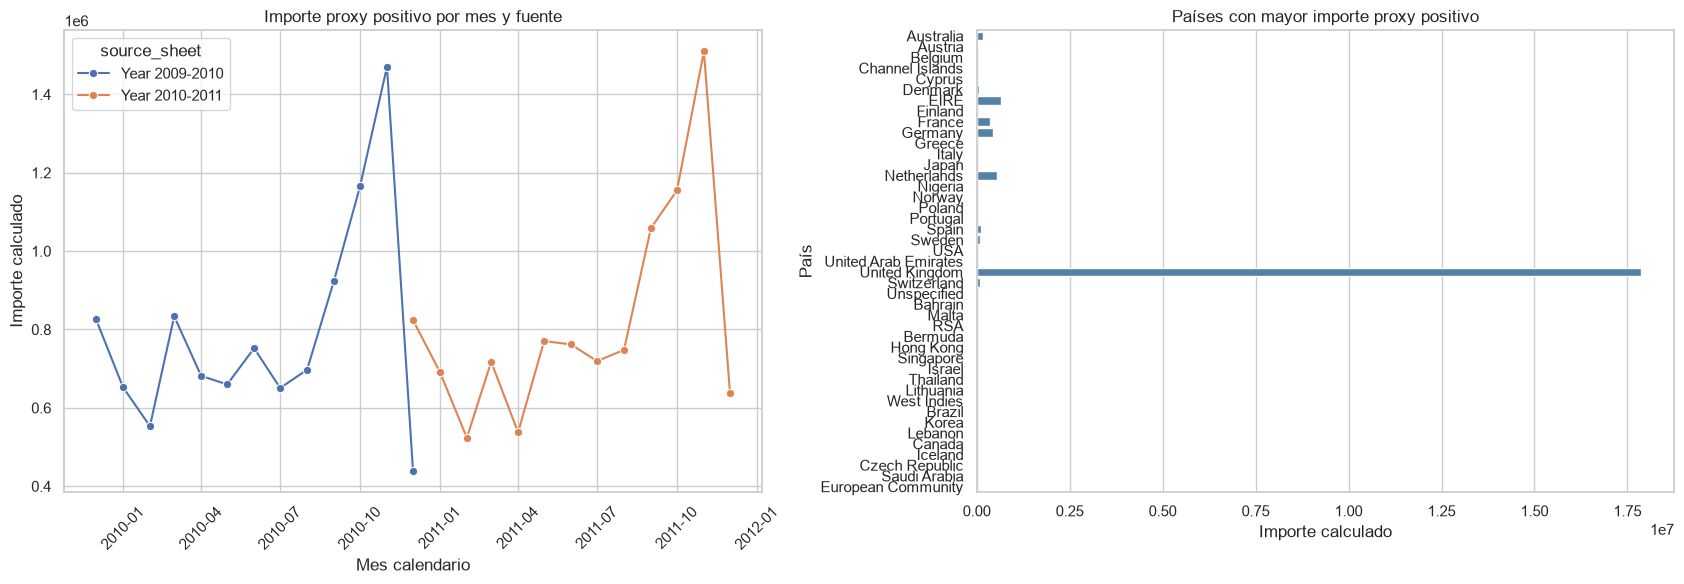

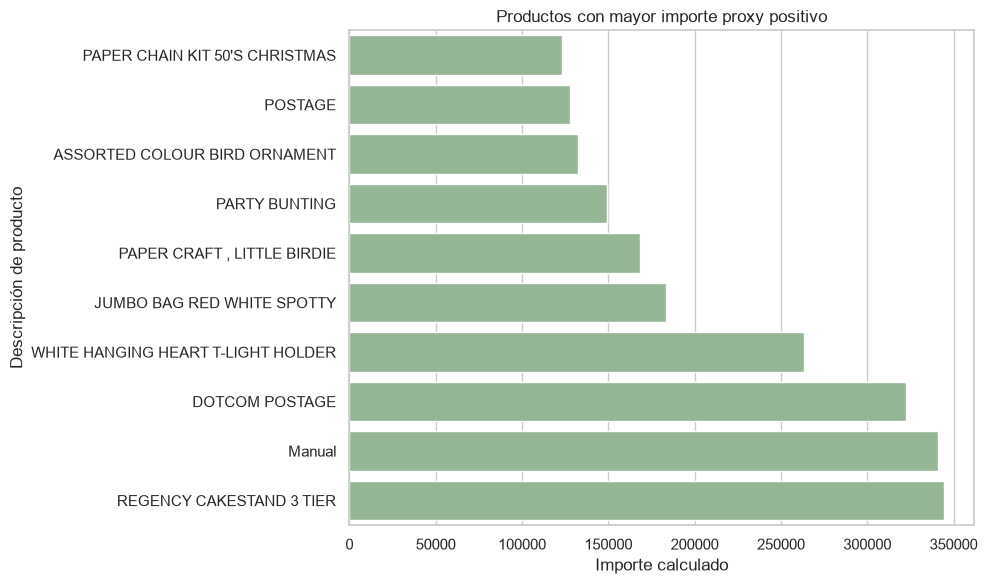

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.lineplot(
    data=monthly, x="calendar_month", y="importe_proxy", hue="source_sheet",
    marker="o", ax=axes[0],
)
axes[0].set_title("Importe proxy positivo por mes y fuente")
axes[0].set_xlabel("Mes calendario")
axes[0].set_ylabel("Importe calculado")
axes[0].tick_params(axis="x", rotation=45)

country_plot = top_countries.reset_index().sort_values("importe_proxy", ascending=True)
sns.barplot(data=country_plot, x="importe_proxy", y="country", color="steelblue", ax=axes[1])
axes[1].set_title("Países con mayor importe proxy positivo")
axes[1].set_xlabel("Importe calculado")
axes[1].set_ylabel("País")
plt.tight_layout()
plt.show()

product_plot = top_products.reset_index().sort_values("importe_proxy", ascending=True)
plt.figure(figsize=(10, 6))
sns.barplot(data=product_plot, x="importe_proxy", y="description", color="darkseagreen")
plt.title("Productos con mayor importe proxy positivo")
plt.xlabel("Importe calculado")
plt.ylabel("Descripción de producto")
plt.tight_layout()
plt.show()

## 4. Distribuciones de cantidades y precios

Las distribuciones son sesgadas y tienen valores extremos; por eso los histogramas usan `log10` de la magnitud. La transformación logarítmica es solo visual: no cambia los datos ni elimina observaciones.

,Caso,Filas
0,Precio cero,6202
1,Precio negativo,5
2,Precio positivo sobre cerca IQR,68100
3,Cantidad negativa,22950
4,Magnitud de cantidad sobre cerca IQR,115571
5,Duplicado exacto marcado,23430


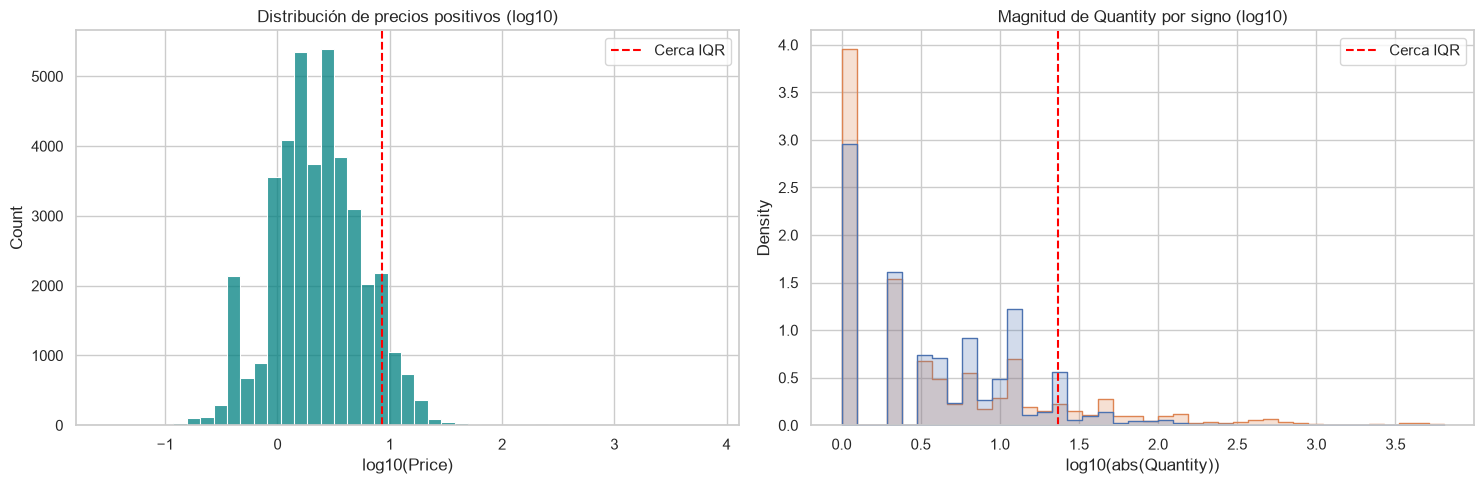

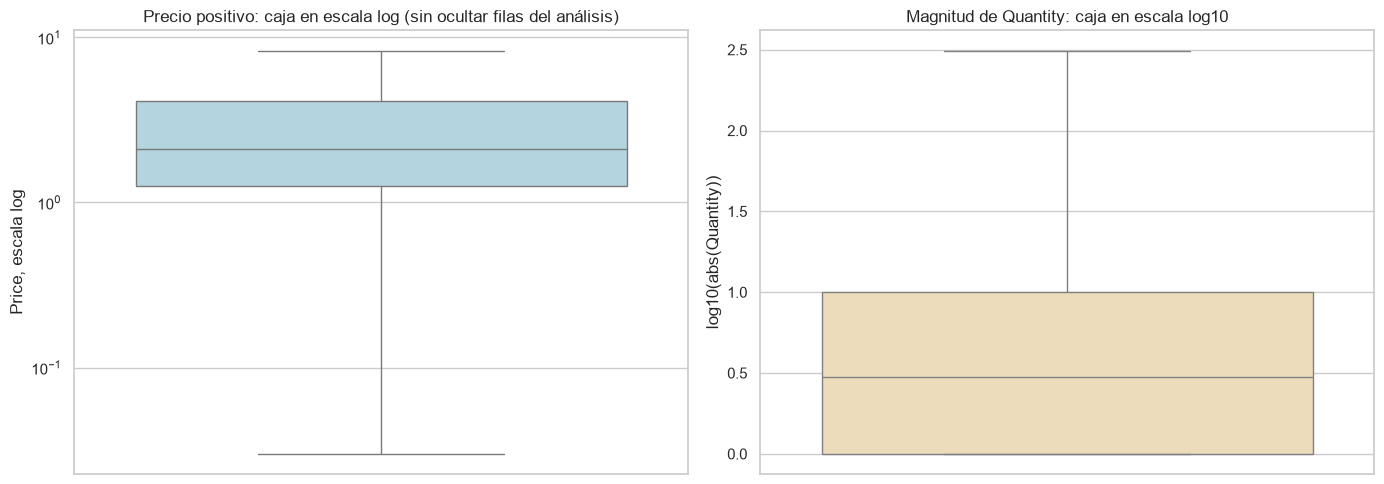

In [5]:
positive_prices = data.loc[data["price"] > 0, "price"].dropna()
price_q1, price_q3 = positive_prices.quantile([0.25, 0.75])
price_iqr_fence = float(price_q3 + 1.5 * (price_q3 - price_q1))
absolute_quantity = data["quantity"].abs().dropna()
quantity_q1, quantity_q3 = absolute_quantity.quantile([0.25, 0.75])
quantity_iqr_fence = float(quantity_q3 + 1.5 * (quantity_q3 - quantity_q1))

distribution_counts = pd.DataFrame([
    ("Precio cero", int(data["is_zero_price"].sum())),
    ("Precio negativo", int(data["is_negative_price"].sum())),
    ("Precio positivo sobre cerca IQR", int(data["is_price_iqr_outlier"].sum())),
    ("Cantidad negativa", int(data["is_negative_quantity"].sum())),
    ("Magnitud de cantidad sobre cerca IQR", int(data["is_quantity_iqr_outlier"].sum())),
    ("Duplicado exacto marcado", int(data["is_exact_duplicate"].sum())),
], columns=["Caso", "Filas"])
display(distribution_counts)

rng = np.random.default_rng(42)
price_sample = positive_prices.sample(n=min(40000, len(positive_prices)), random_state=42)
quantity_rows = data.loc[data["quantity"].ne(0), ["quantity", "period"]].copy()
quantity_sample = quantity_rows.sample(n=min(50000, len(quantity_rows)), random_state=42)
quantity_sample["log10_abs_quantity"] = np.log10(quantity_sample["quantity"].abs().astype(float))
quantity_sample["signo"] = np.where(quantity_sample["quantity"] > 0, "Cantidad positiva", "Cantidad negativa")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(np.log10(price_sample.astype(float)), bins=45, color="teal", ax=axes[0])
axes[0].axvline(np.log10(price_iqr_fence), color="red", linestyle="--", label="Cerca IQR")
axes[0].set_title("Distribución de precios positivos (log10)")
axes[0].set_xlabel("log10(Price)")
axes[0].legend()
sns.histplot(
    data=quantity_sample, x="log10_abs_quantity", hue="signo", bins=40,
    element="step", stat="density", common_norm=False, ax=axes[1],
)
axes[1].axvline(np.log10(quantity_iqr_fence), color="red", linestyle="--", label="Cerca IQR")
axes[1].set_title("Magnitud de Quantity por signo (log10)")
axes[1].set_xlabel("log10(abs(Quantity))")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=price_sample.astype(float), showfliers=False, color="lightblue", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Precio positivo: caja en escala log (sin ocultar filas del análisis)")
axes[0].set_ylabel("Price, escala log")
sns.boxplot(y=quantity_sample["log10_abs_quantity"], showfliers=False, color="wheat", ax=axes[1])
axes[1].set_title("Magnitud de Quantity: caja en escala log10")
axes[1].set_ylabel("log10(abs(Quantity))")
plt.tight_layout()
plt.show()

## 5. Relaciones entre variables

Se relacionan precio unitario y magnitud de cantidad en una muestra reproducible. La correlación de Spearman se calcula sobre logaritmos para reducir la influencia de la escala; no implica causalidad. El importe de línea depende matemáticamente de cantidad y precio.

Correlación Spearman entre log10(Price) y log10(abs(Quantity)): -0.421


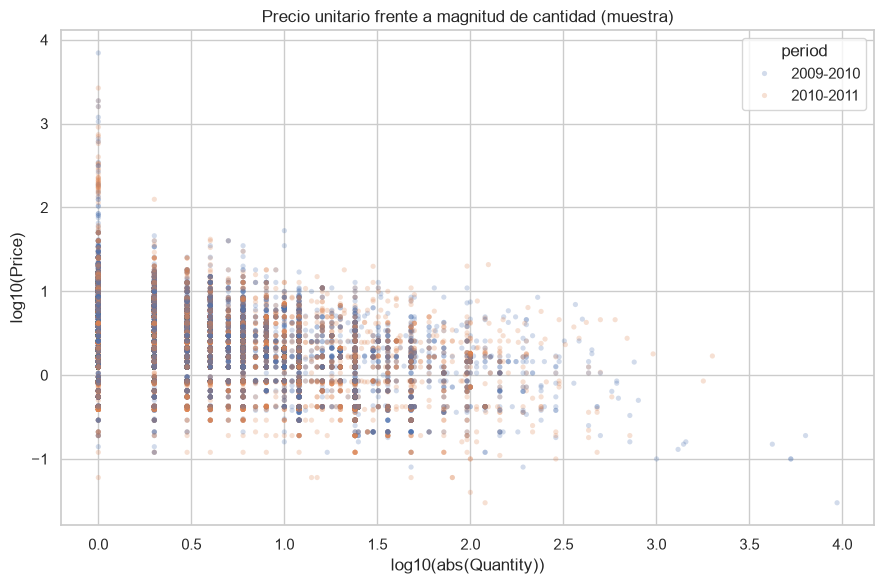

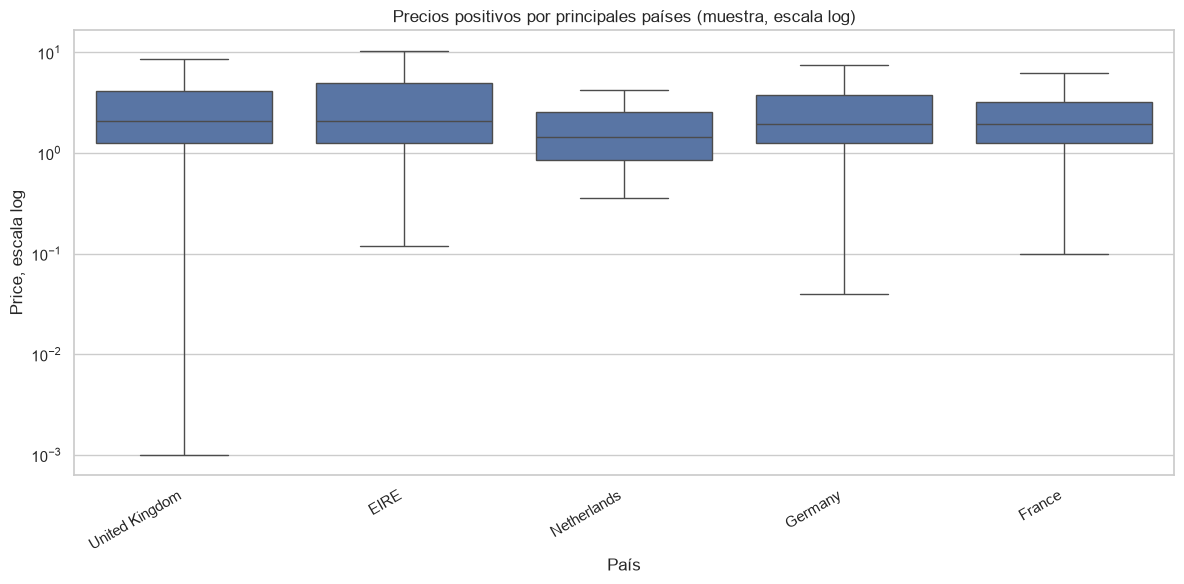

In [6]:
pairs = data.loc[
    data["price"].gt(0) & data["quantity"].ne(0),
    ["price", "quantity", "period", "country"],
].copy()
pairs["log10_price"] = np.log10(pairs["price"].astype(float))
pairs["log10_abs_quantity"] = np.log10(pairs["quantity"].abs().astype(float))
spearman_log_correlation = pairs[["log10_price", "log10_abs_quantity"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación Spearman entre log10(Price) y log10(abs(Quantity)): {spearman_log_correlation:.3f}")
pair_sample = pairs.sample(n=min(30000, len(pairs)), random_state=42)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pair_sample, x="log10_abs_quantity", y="log10_price", hue="period",
    alpha=0.25, s=14, linewidth=0,
)
plt.title("Precio unitario frente a magnitud de cantidad (muestra)")
plt.xlabel("log10(abs(Quantity))")
plt.ylabel("log10(Price)")
plt.tight_layout()
plt.show()

country_order = list(top_countries.head(5).index)
price_country_sample = data.loc[
    data["country"].isin(country_order) & data["price"].gt(0), ["country", "price"]
].copy()
price_country_sample = price_country_sample.sample(
    n=min(40000, len(price_country_sample)), random_state=42
)
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=price_country_sample, x="country", y="price", order=country_order,
    showfliers=False,
)
plt.yscale("log")
plt.title("Precios positivos por principales países (muestra, escala log)")
plt.xlabel("País")
plt.ylabel("Price, escala log")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Interpretación para el negocio

Los indicadores siguientes describen el extracto disponible. Las conclusiones sobre cliente están limitadas por `Customer ID` faltante; los importes son cálculos transaccionales y deben conciliarse con la definición contable antes de usarlos como ingresos.

In [7]:
top_period = period_summary["importe_proxy_positivo"].idxmax()
top_country = by_country.index[0]
top_product = by_product.index[0]
top_customer = by_customer.index[0] if len(by_customer) else None
top_country_share = float(by_country.iloc[0]["importe_proxy"] / positive_amount_total * 100)
top_product_share = float(by_product.iloc[0]["importe_proxy"] / positive_amount_total * 100)
customer_missing_pct = float(data["customer_id"].isna().mean() * 100)
cancellation_pct = float(data["is_cancellation"].mean() * 100)
negative_quantity_pct = float(data["is_negative_quantity"].mean() * 100)
price_outlier_pct = float(data["is_price_iqr_outlier"].mean() * 100)
quantity_outlier_pct = float(data["is_quantity_iqr_outlier"].mean() * 100)

business_findings = pd.DataFrame([
    ("Periodo de mayor importe proxy", str(top_period), float(period_summary.loc[top_period, "importe_proxy_positivo"])),
    ("País líder y participación", str(top_country), top_country_share),
    ("Producto líder y participación", str(top_product), top_product_share),
    ("Importe proxy positivo total", "líneas positivas no C/A", positive_amount_total),
    ("Importe firmado de todas las líneas", "incluye devoluciones/ajustes", signed_amount_total),
    ("Customer ID faltante (%)", "limita segmentación por cliente", customer_missing_pct),
    ("Facturas C (%)", "separar de ventas brutas", cancellation_pct),
    ("Cantidad negativa (%)", "posibles devoluciones/ajustes", negative_quantity_pct),
    ("Precio sobre cerca IQR (%)", "alerta exploratoria, no error automático", price_outlier_pct),
    ("Magnitud de cantidad sobre cerca IQR (%)", "alerta exploratoria, no error automático", quantity_outlier_pct),
], columns=["Hallazgo", "Contexto", "Valor"])
display(business_findings)

print(f"El periodo {top_period} concentra el mayor importe proxy positivo.")
print(f"{top_country} aporta {top_country_share:.1f}% del importe proxy; revisar la concentración geográfica y su evolución por fuente.")
print(f"El producto {top_product} aporta {top_product_share:.2f}% del importe proxy; validar disponibilidad y margen antes de priorizarlo comercialmente.")
print(f"{customer_missing_pct:.1f}% de las filas no tiene Customer ID: las conclusiones de retención/valor de cliente son parciales.")
print(f"El importe firmado ({signed_amount_total:,.2f}) no debe interpretarse como venta neta contable sin conciliar cancelaciones C, ajustes A y devoluciones.")
print(f"La asociación log-precio/log-cantidad (Spearman {spearman_log_correlation:.3f}) es descriptiva y no prueba causalidad.")
print("Los outliers IQR se conservan: pueden ser pedidos por volumen, artículos especiales o ajustes que requieren revisión comercial.")

,Hallazgo,Contexto,Valor
0,Periodo de mayor importe proxy,2010-2011,1.065564e+07
1,País líder y participación,United Kingdom,8.520329e+01
2,Producto líder y participación,22423,1.643788e+00
3,Importe proxy positivo total,líneas positivas no C/A,2.096153e+07
4,Importe firmado de todas las líneas,incluye devoluciones/ajustes,1.928725e+07
5,Customer ID faltante (%),limita segmentación por cliente,2.276687e+01
6,Facturas C (%),separar de ventas brutas,1.826357e+00
7,Cantidad negativa (%),posibles devoluciones/ajustes,2.150143e+00
8,Precio sobre cerca IQR (%),"alerta exploratoria, no error automático",6.380162e+00
9,Magnitud de cantidad sobre cerca IQR (%),"alerta exploratoria, no error automático",1.082763e+01


El periodo 2010-2011 concentra el mayor importe proxy positivo.
United Kingdom aporta 85.2% del importe proxy; revisar la concentración geográfica y su evolución por fuente.
El producto 22423 aporta 1.64% del importe proxy; validar disponibilidad y margen antes de priorizarlo comercialmente.
22.8% de las filas no tiene Customer ID: las conclusiones de retención/valor de cliente son parciales.
El importe firmado (19,287,250.57) no debe interpretarse como venta neta contable sin conciliar cancelaciones C, ajustes A y devoluciones.
La asociación log-precio/log-cantidad (Spearman -0.421) es descriptiva y no prueba causalidad.
Los outliers IQR se conservan: pueden ser pedidos por volumen, artículos especiales o ajustes que requieren revisión comercial.
